# Fresnel and polarization compensation in a stigmatic diopter

**Question.** A single refracting surface $\mathcal G$ images an axial point exactly. Its local Fresnel transmission and the tilt of the $p$ field still distort the focus. Can a prepared entrance field on $\mathcal G$ undo both, so that the **transverse** focal field becomes the Airy pattern? What does that cost at fixed incident power?

The diopter is a Cartesian oval (GOTS) between an object point $z_0=-10$ mm in air ($n_o=1$) and its image $z_i=6$ mm in fused silica ($n_i=1.46$), for $\lambda_0=532$ nm. Its clear aperture on $\mathcal G$ gives the image-space NA $=0.84096$. The index $n_i$ is inferred: it reproduces the reference uncompensated first-minimum radii (about 0.52 µm along $x$ and 0.55 µm along $y$). Change it in the first code cell to use another material.

We compare two x-polarized entrance fields on $\mathcal G$ carrying **the same incident power**:

1. **Uncompensated:** constant transverse amplitude and polarization.
2. **Compensated:** $p$ and $s$ amplitudes divided by the diopter's own transfer weights $w_p$, $w_s$.

No aplanatic objective, sine condition or Richards–Wolf apodization is assumed. Everything follows from the surface geometry, local Fresnel transmission and energy conservation along ray tubes. Maps use the hot color map; black segments show the transverse polarization direction.

## 1. Model: local Fresnel transmission and energy conservation

**Entrance field on $\mathcal G$.** Each surface point $Q$, labelled by its radius $r$ and azimuth $\phi$, receives the ray from $P_0=(0,0,z_0)$ with direction $\mathbf d_o$ and tilt $\tan a_0=r/(z_Q-z_0)$. An x-polarized field made transverse to that ray, with $p$ and $s$ amplitudes $a_p(r)$ and $a_s(r)$, is

$$
 \mathbf E_0=a_p\cos\phi\,(\mathbf e_\rho-\tan a_0\,\mathbf e_z)-a_s\sin\phi\,\mathbf e_\phi .
$$

$a_p=a_s=1$ is the uncompensated field: $E_{0x}=1$, $E_{0y}=0$, $E_{0z}=-\tan a_0\cos\phi$.

**Local Fresnel transmission.** At $Q$ the true oval normal $\mathbf n$ gives the transmitted direction $\mathbf d_i$ by Snell's law, and

$$
 \mathbf E_t=\bigl(t_p\,\mathbf p_i\otimes\mathbf p_o+t_s\,\mathbf s\otimes\mathbf s\bigr)\mathbf E_0 ,
$$

the same operator used by the library's interface transmission. Stigmatism means every $\mathbf d_i$ points to $F=(0,0,z_i)$ and every ray arrives in phase; the notebook checks both.

**Energy conservation to the focal spectrum.** Write the focal field as $\mathbf E(\mathbf r)=\int\mathbf A(\boldsymbol\kappa)\,e^{i\mathbf k\cdot\mathbf r}\,d^2\kappa$ with $\boldsymbol\kappa=k_i\,\mathbf d_{i\perp}$. The power $\tfrac{n_i}{2Z_0}|\mathbf E_t|^2(\mathbf d_i\cdot\mathbf n)\,dA$ crossing a surface patch fills the solid angle $d\Omega=(\mathbf d_i\cdot\mathbf n)\,dA/L_i^2$ seen from $F$, and $d^2\kappa=k_i^2\cos\theta\,d\Omega$. Equating it with the spectral power $\tfrac{n_i}{2Z_0}(2\pi)^2|\mathbf A|^2\cos\theta\,d^2\kappa$ gives

$$
 \mathbf A(\boldsymbol\kappa)=\frac{L_i}{2\pi k_i\cos\theta}\,\mathbf E_t(Q),
$$

with $L_i=|F-Q|$ and $\cos\theta=\mathbf d_i\cdot\mathbf e_z$. The notebook verifies this power balance numerically.

**Transfer weights and compensation.** By symmetry an x-polarized entrance field gives $A_x=c_0+c_2\cos2\psi$, $A_y=c_2\sin2\psi$, $A_z=c_z\cos\psi$ in the spectrum azimuth $\psi$. The $p$ and $s$ channels have transfer weights

$$
 w_p(r)=A_x\big|_{a_p=1,\,a_s=0,\ \psi=0},\qquad
 w_s(r)=A_x\big|_{a_p=0,\,a_s=1,\ \psi=\pi/2}.
$$

They contain $t_p$, $t_s$, the $p$-tilt, the ray-tube factor $L_i/\cos\theta$ and the entrance obliquity. Choosing $a_p=C\,w_p(0)/w_p$ and $a_s=C\,w_s(0)/w_s$ makes $\mathbf A_\perp$ uniform and parallel to $\mathbf e_x$ over the NA disk, $c_2=0$. The transverse focal field is then exactly the Airy amplitude $2J_1(v)/v$, $v=k_0\,\mathrm{NA}\,\rho$. $C$ fixes equal incident power. The longitudinal field follows from transversality and is not prescribed.

**Focal field.** The $\psi$ integrals give Bessel functions:

$$
 E_x=F_0-F_2\cos2\varphi,\quad E_y=-F_2\sin2\varphi,\quad E_z=iF_z\cos\varphi,
$$
$$
 F_0=2\pi\!\int\! c_0J_0(\kappa\rho)\,\kappa\,d\kappa,\quad
 F_2=2\pi\!\int\! c_2J_2(\kappa\rho)\,\kappa\,d\kappa,\quad
 F_z=2\pi\!\int\! c_zJ_1(\kappa\rho)\,\kappa\,d\kappa,
$$

evaluated with Gauss–Legendre quadrature in $\kappa\in[0,k_0\mathrm{NA}]$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from matplotlib.colors import LogNorm
from matplotlib.patheffects import Normal, Stroke
from matplotlib.ticker import FuncFormatter
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
from scipy.special import j1, jv
from vecdiff_general.interfaces.directions import transmitted_direction
from vecdiff_general.interfaces.fresnel import (
    apply_fresnel,
    fresnel_transmission_matrix,
)
from vecdiff_general.visualization import plot_polarization

%matplotlib inline

plt.rcParams.update({"figure.dpi": 180, "font.size": 11})

um, mm = 1e-6, 1e-3
wavelength = 532e-9
z0, zi = -10 * mm, 6 * mm
no, ni = 1.0, 1.46  # object in air, image in fused silica (inferred index)
numerical_aperture = 0.84096
k0 = 2 * np.pi / wavelength
ki = ni * k0
kappa_max = k0 * numerical_aperture

surface = optics.CartesianOval.from_conjugates(no, z0, ni, zi)
object_point = np.array([0.0, 0.0, z0])
image_point = np.array([0.0, 0.0, zi])
parameters = (
    rf"$z_0$ = {z0 / mm:.3f} mm; $z_i$ = {zi / mm:.3f} mm; "
    rf"$\lambda_0$ = {wavelength * 1e9:.0f} nm; NA = {numerical_aperture:.5f}"
)


def rays(r, phi):
    """Surface point, normal, incident and transmitted directions for labels (r, phi)."""
    r, phi = np.broadcast_arrays(np.asarray(r, float), np.asarray(phi, float))
    xy = np.stack((r * np.cos(phi), r * np.sin(phi)), axis=-1)
    point = surface.points(xy)
    normal = surface.normals(xy)
    incident = point - object_point
    incident /= np.linalg.norm(incident, axis=-1)[..., None]
    transmitted = transmitted_direction(incident, normal, no, ni).real
    to_image = image_point - point
    distance = np.linalg.norm(to_image, axis=-1)
    return {
        "r": r,
        "phi": phi,
        "point": point,
        "normal": normal,
        "incident": incident,
        "transmitted": transmitted,
        "to_image": to_image / distance[..., None],
        "distance": distance,
        "area": surface.area_jacobian(xy),
    }


def entrance_field(ray, ap, as_):
    """x-polarized field made transverse to each incident ray (section 1)."""
    phi, r = ray["phi"], ray["r"]
    tan_a0 = r / (ray["point"][..., 2] - z0)
    zeros = np.zeros_like(phi)
    e_rho = np.stack((np.cos(phi), np.sin(phi), zeros), axis=-1)
    e_phi = np.stack((-np.sin(phi), np.cos(phi), zeros), axis=-1)
    e_z = np.stack((zeros, zeros, zeros + 1), axis=-1)
    return (ap * np.cos(phi))[..., None] * (e_rho - tan_a0[..., None] * e_z) - (
        as_ * np.sin(phi)
    )[..., None] * e_phi


def transmitted_field(ray, ap, as_):
    matrix = fresnel_transmission_matrix(
        ray["incident"], ray["transmitted"], ray["normal"], no, ni
    )
    return apply_fresnel(entrance_field(ray, ap, as_), matrix)


def spectrum_amplitude(ray, ap, as_):
    """Energy-conserving ray-tube map from the surface field to A(kappa)."""
    cos_theta = ray["transmitted"][..., 2]
    scale = ray["distance"] / (2 * np.pi * ki * cos_theta)
    return transmitted_field(ray, ap, as_) * scale[..., None]


def sine_of_aperture(r):
    return -rays(r, 0.0)["to_image"][..., 0]


# Largest radius on the vertex-connected oval branch, then the NA aperture.
top = 0.1 * mm
while True:
    try:
        sine_of_aperture(1.01 * top)
    except ValueError:
        break
    top *= 1.01
aperture = brentq(
    lambda r: ni * sine_of_aperture(r) - numerical_aperture, 0.1 * mm, top
)
r_table = np.linspace(0, aperture, 40001)
sine_table = sine_of_aperture(r_table)
assert np.all(np.diff(sine_table) > 0)

check = rays(r_table[1:], np.linspace(0, 2 * np.pi, len(r_table) - 1))
stigmatic_error = np.max(np.linalg.norm(check["transmitted"] - check["to_image"], axis=-1))
path = no * np.linalg.norm(check["point"] - object_point, axis=-1) + ni * check["distance"]
path_error = np.ptp(path) / wavelength
incidence = np.degrees(np.arccos(np.sum(check["incident"] * check["normal"], axis=-1)))
print(f"Clear aperture on G: a = {aperture / mm:.5f} mm; vertex sag at the rim = {rays(aperture, 0.0)['point'][2] / mm:.4f} mm")
print(f"Stigmatism: max |d_i - (F - Q)/|F - Q|| = {stigmatic_error:.1e}; optical-path spread = {path_error:.1e} λ0")
print(f"Largest incidence angle on G: {incidence.max():.2f}°")
assert stigmatic_error < 1e-12 and path_error < 1e-6

Clear aperture on G: a = 2.29106 mm; vertex sag at the rim = 2.7486 mm
Stigmatism: max |d_i - (F - Q)/|F - Q|| = 5.6e-16; optical-path spread = 2.0e-11 λ0
Largest incidence angle on G: 88.57°


## 2. Transfer weights of the diopter

The weights $w_p$ and $w_s$ follow each surface point from the entrance field to the focal spectrum. They combine the local Fresnel coefficients, the $p$ tilt, the entrance obliquity and the ray-tube factor $L_i/\cos\theta$ of energy conservation. Their unequal decline toward the rim is what elongates and depolarizes the uncompensated focus. The compensated amplitudes are their normalized inverses, scaled by $C$ for equal incident power. Incident power through $\mathcal G$ is $\tfrac{n_o}{2Z_0}\int|\mathbf E_0|^2(\mathbf d_o\cdot\mathbf n)\,dA$.

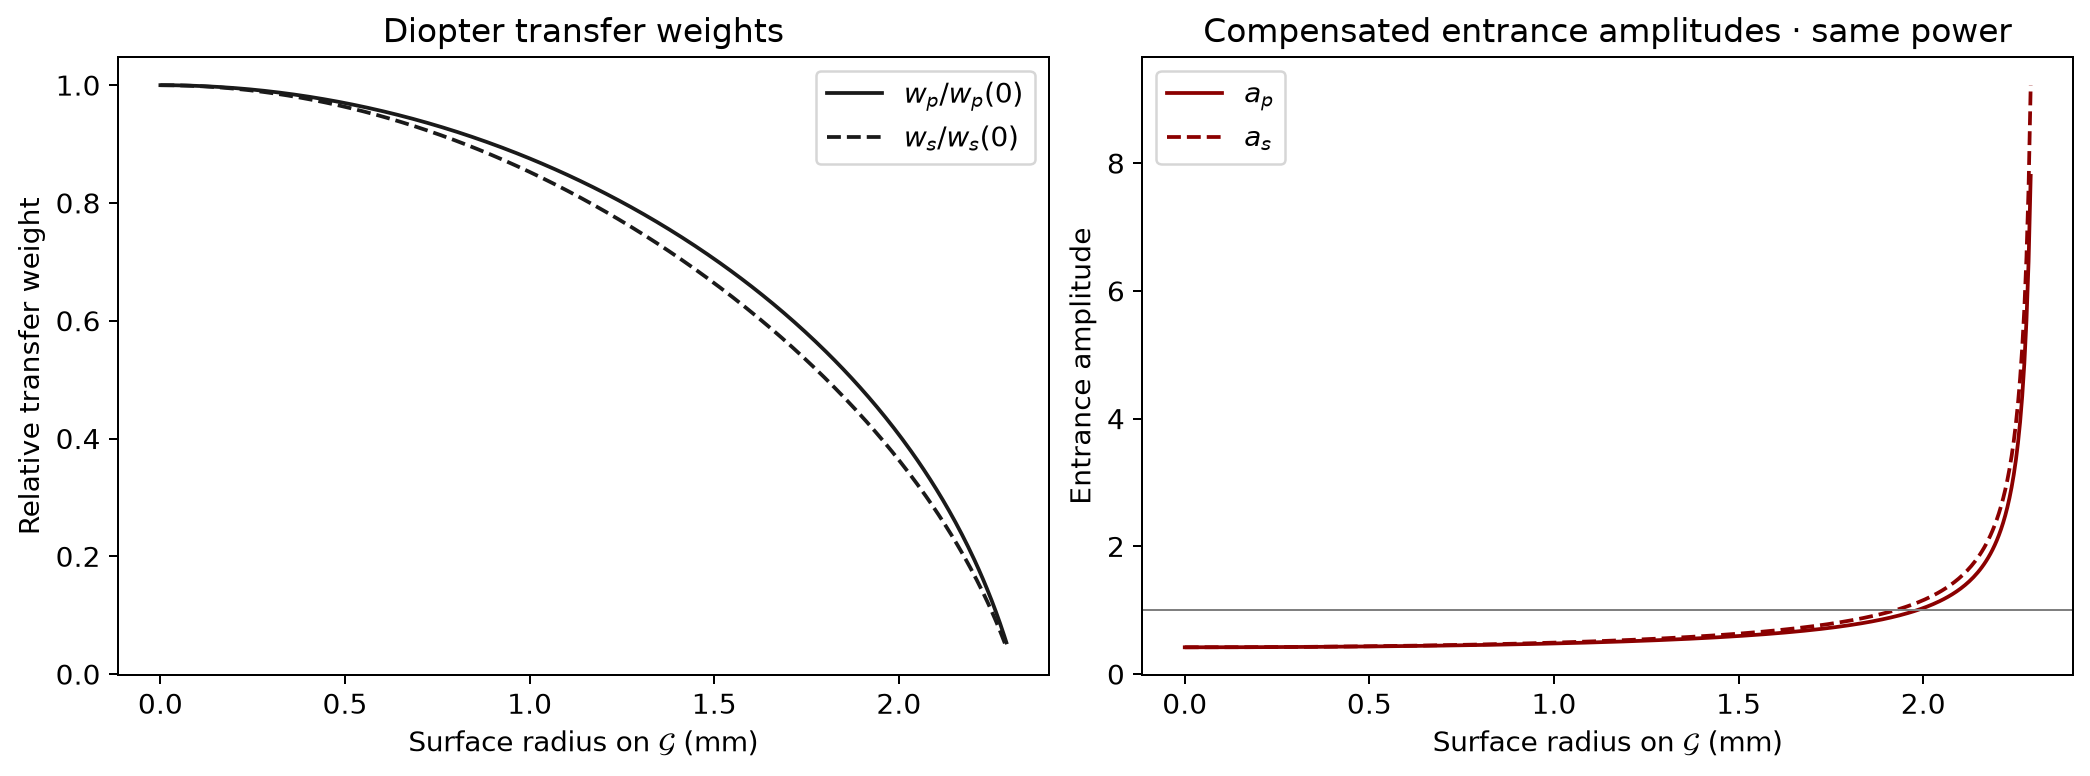

C = 0.421238
Uncompensated: transmitted / incident power at G = 0.858236
Compensated: transmitted / incident power at G = 0.536916


In [2]:
tiny = 1e-9 * aperture


def transfer_weights(r):
    r = np.maximum(np.asarray(r, float), tiny)
    wp = spectrum_amplitude(rays(r, np.pi), 1.0, 0.0)[..., 0].real
    ws = spectrum_amplitude(rays(r, 1.5 * np.pi), 0.0, 1.0)[..., 0].real
    return wp, ws


wp0, ws0 = transfer_weights(0.0)
assert np.isclose(wp0, ws0, rtol=1e-12)

# Surface quadrature: Gauss-Legendre in r, uniform in phi.
nodes, weights = np.polynomial.legendre.leggauss(400)
r_nodes = 0.5 * aperture * (nodes + 1)
r_weights = 0.5 * aperture * weights
phi_nodes = (np.arange(128) + 0.5) * 2 * np.pi / 128
R, PHI = np.meshgrid(r_nodes, phi_nodes, indexing="ij")
surface_rays = rays(R, PHI)
cell = (r_weights * r_nodes)[:, None] * (2 * np.pi / 128) * surface_rays["area"]


def powers(amplitudes):
    """Incident and transmitted power through G (common factor 1/(2 Z0) omitted)."""
    ap, as_ = amplitudes(R)
    incident = entrance_field(surface_rays, ap, as_)
    transmitted = transmitted_field(surface_rays, ap, as_)
    cos_o = np.sum(surface_rays["incident"] * surface_rays["normal"], axis=-1)
    cos_i = np.sum(surface_rays["transmitted"] * surface_rays["normal"], axis=-1)
    p_in = no * np.sum(np.sum(abs(incident) ** 2, axis=-1) * cos_o * cell)
    p_out = ni * np.sum(np.sum(abs(transmitted) ** 2, axis=-1) * cos_i * cell)
    return p_in, p_out


def uniform_amplitudes(r):
    return np.ones_like(r), np.ones_like(r)


def raw_compensated_amplitudes(r):
    wp, ws = transfer_weights(r)
    return wp0 / wp, ws0 / ws


C = np.sqrt(powers(uniform_amplitudes)[0] / powers(raw_compensated_amplitudes)[0])


def compensated_amplitudes(r):
    ap, as_ = raw_compensated_amplitudes(r)
    return C * ap, C * as_


illuminations = {
    "Uncompensated": uniform_amplitudes,
    "Compensated": compensated_amplitudes,
}
power = {name: powers(amplitudes) for name, amplitudes in illuminations.items()}
assert np.isclose(power["Uncompensated"][0], power["Compensated"][0], rtol=1e-12)

radius = np.linspace(0, aperture, 400)
wp, ws = transfer_weights(radius)
ap, as_ = compensated_amplitudes(radius)
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout="constrained")
axes[0].plot(radius / mm, wp / wp0, "-", color="0.1", label="$w_p/w_p(0)$")
axes[0].plot(radius / mm, ws / ws0, "--", color="0.1", label="$w_s/w_s(0)$")
axes[0].set(
    xlabel="Surface radius on $\\mathcal{G}$ (mm)",
    ylabel="Relative transfer weight",
    title="Diopter transfer weights",
)
axes[1].plot(radius / mm, ap, "-", color="#8B0000", label="$a_p$")
axes[1].plot(radius / mm, as_, "--", color="#8B0000", label="$a_s$")
axes[1].axhline(1, color="0.5", lw=0.8)
axes[1].set(
    xlabel="Surface radius on $\\mathcal{G}$ (mm)",
    ylabel="Entrance amplitude",
    title="Compensated entrance amplitudes · same power",
)
for axis in axes:
    axis.legend()
plt.show()

print(f"C = {C:.6f}")
for name, (p_in, p_out) in power.items():
    print(f"{name}: transmitted / incident power at G = {p_out / p_in:.6f}")

## 3. Entrance fields on $\mathcal G$

Both entrance fields are shown on the same logarithmic scale as functions of the surface radius label, with their transverse polarization. A linear scale would be dominated by the compensated rim, where incidence on $\mathcal G$ approaches grazing and the required amplitude grows sharply. The compensated field grows toward the rim, where $w_p$ and $w_s$ are smallest, and its polarization rotates away from $x$ wherever $a_p\ne a_s$.

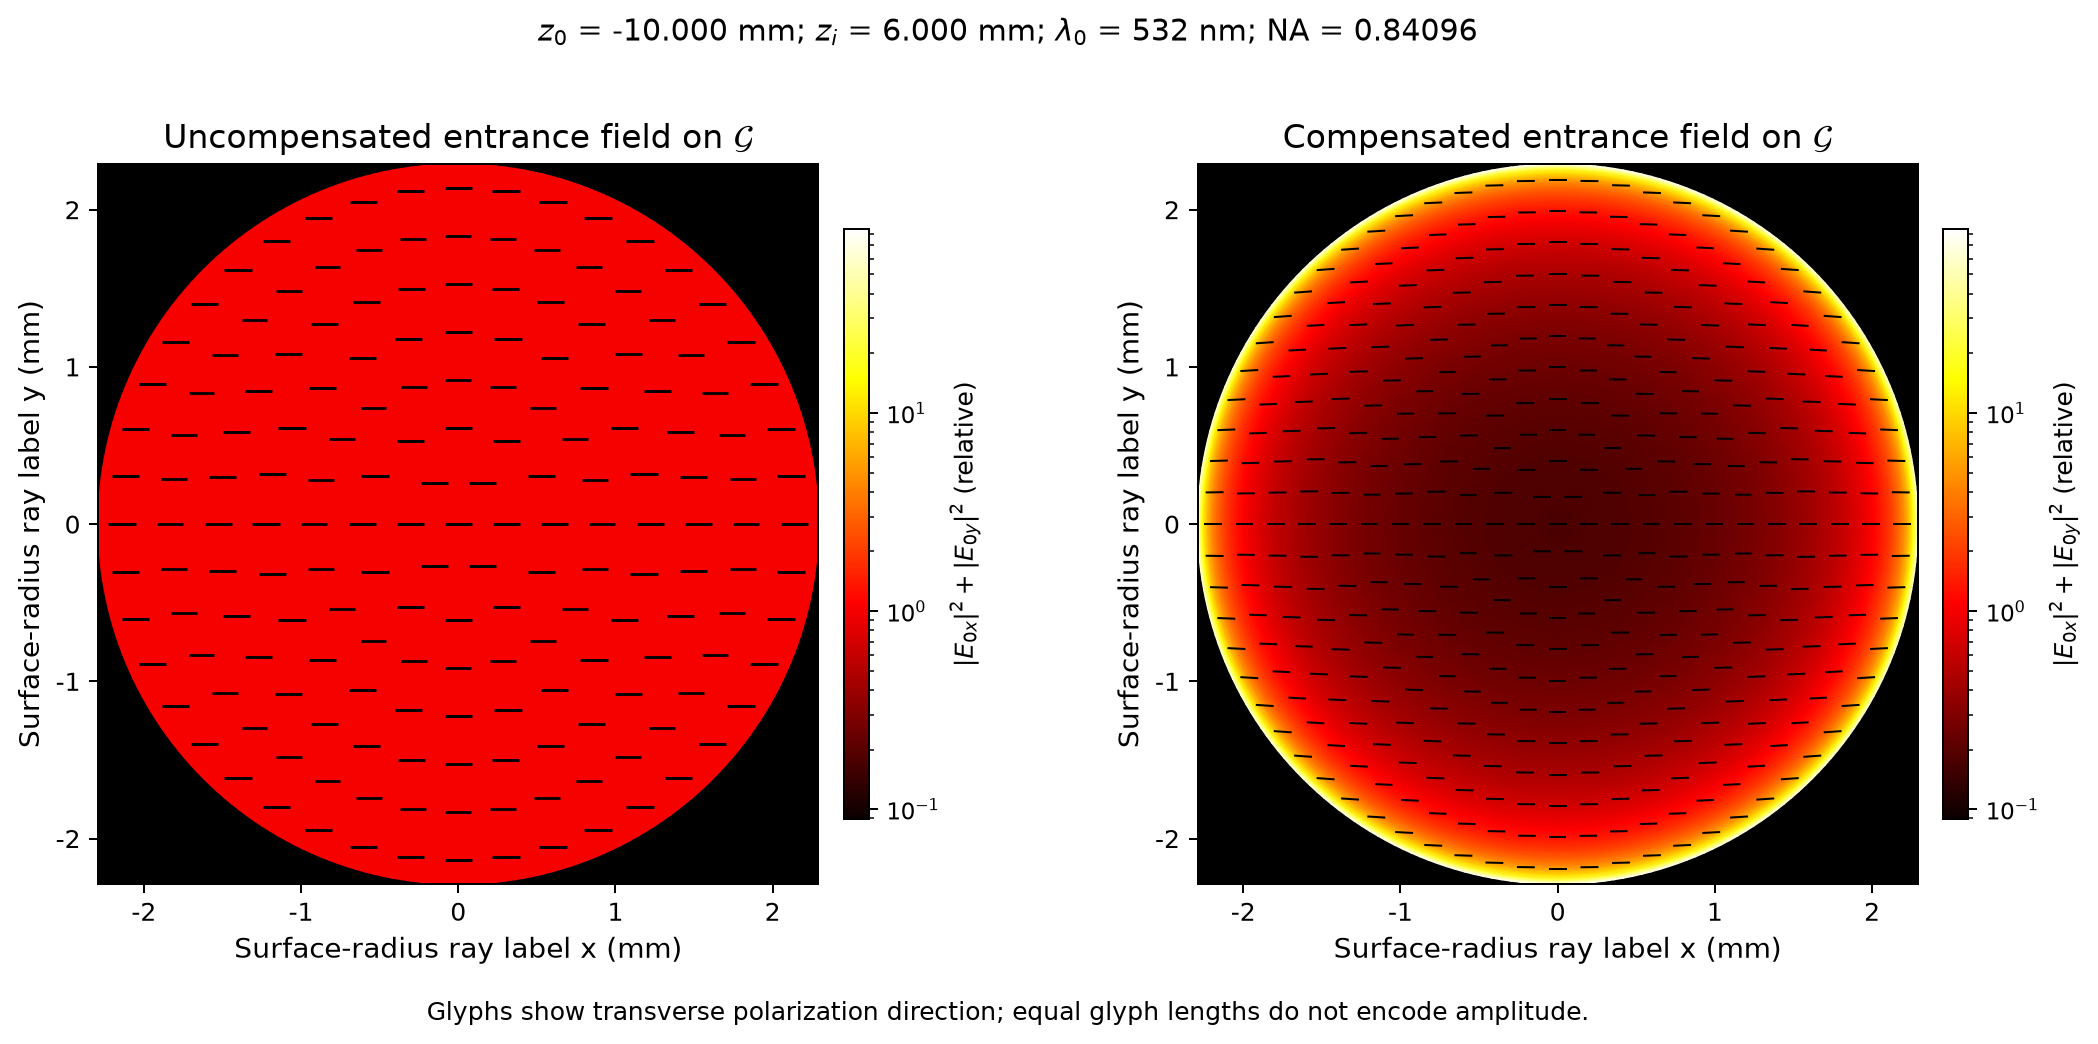

In [3]:
entrance_grid = optics.PolarGrid(
    np.linspace(0, aperture, 81), np.arange(240) * 2 * np.pi / 240
)
RG, PG = np.meshgrid(entrance_grid.radius, entrance_grid.azimuth, indexing="ij")
entrance_rays = rays(np.maximum(RG, tiny), PG)
entrance = {
    name: optics.ElectricField(
        entrance_grid, wavelength, entrance_field(entrance_rays, *amplitudes(RG))
    )
    for name, amplitudes in illuminations.items()
}
maximum = max(
    np.max(abs(field.values[..., 0]) ** 2 + abs(field.values[..., 1]) ** 2)
    for field in entrance.values()
)
millimetres = FuncFormatter(lambda value, _: f"{value / 1000:g}")
minimum = min(
    np.min(abs(field.values[..., 0]) ** 2 + abs(field.values[..., 1]) ** 2)
    for field in entrance.values()
)
figure, axes = plt.subplots(1, 2, figsize=(12, 5.8))
figure.subplots_adjust(left=0.07, right=0.93, bottom=0.15, top=0.84, wspace=0.45)
for axis, (name, field) in zip(axes, entrance.items()):
    plot_polarization(
        field,
        axis=axis,
        title=f"{name} entrance field on $\\mathcal{{G}}$",
        glyph="line",
        glyph_color="black",
        size_scale=None,
        cmap="hot",
        norm=LogNorm(0.5 * minimum, maximum),
        colorbar_label=r"$|E_{0x}|^2 + |E_{0y}|^2$ (relative)",
        min_intensity_fraction=1e-5,
    )
    axis.xaxis.set_major_formatter(millimetres)
    axis.yaxis.set_major_formatter(millimetres)
    axis.set(
        xlabel="Surface-radius ray label x (mm)",
        ylabel="Surface-radius ray label y (mm)",
    )
    axis.set_facecolor("black")
figure.suptitle(parameters, fontsize=12)
figure.text(
    0.5,
    0.02,
    "Glyphs show transverse polarization direction; equal glyph lengths do not encode amplitude.",
    ha="center",
    fontsize=10,
)
plt.show()

## 4. Focal fields and the Airy radius

The maps show the transverse intensity $I_\perp=|E_x|^2+|E_y|^2$, each divided by its on-axis value, on one logarithmic scale from $10^{-5}$ to 1. The scale keeps the three side lobes and the minima between them apart instead of flattening them to black. The window, $\pm1.40$ µm, ends between the third and fourth side lobes of both fields along $x$ and $y$, and the cell counts them.

Three contours are drawn on both maps:

- the **Airy first-zero circle**, $r_A=3.8317/(k_0\,\mathrm{NA})=0.61\,\lambda_0/\mathrm{NA}$;
- the **uncompensated first-minimum contour**, the first radial minimum of $I_\perp$ measured at every azimuth;
- the **compensated first-minimum contour**, measured the same way.

These are first radial minima, not half-maximum radii. The compensated contour falls on the Airy circle, and its glyphs are parallel to $x$ everywhere; the cell asserts that its transverse field equals the Airy amplitude.

Uncompensated: transverse secondary maxima (left, right) in x, y = ((3, 3), (3, 3))
Compensated: transverse secondary maxima (left, right) in x, y = ((3, 3), (3, 3))


Airy first-zero radius r_A = 0.38579 µm
Uncompensated first transverse minimum: x 0.5177 µm, y 0.5471 µm, range 0.5177-0.5471 µm
Compensated first transverse minimum: x 0.3858 µm, y 0.3858 µm, range 0.3858-0.3858 µm
Compensated: max |Ex/Ex(0) - 2J1(v)/v| = 4.4e-14; max |Ey|/|Ex(0)| = 2.1e-18


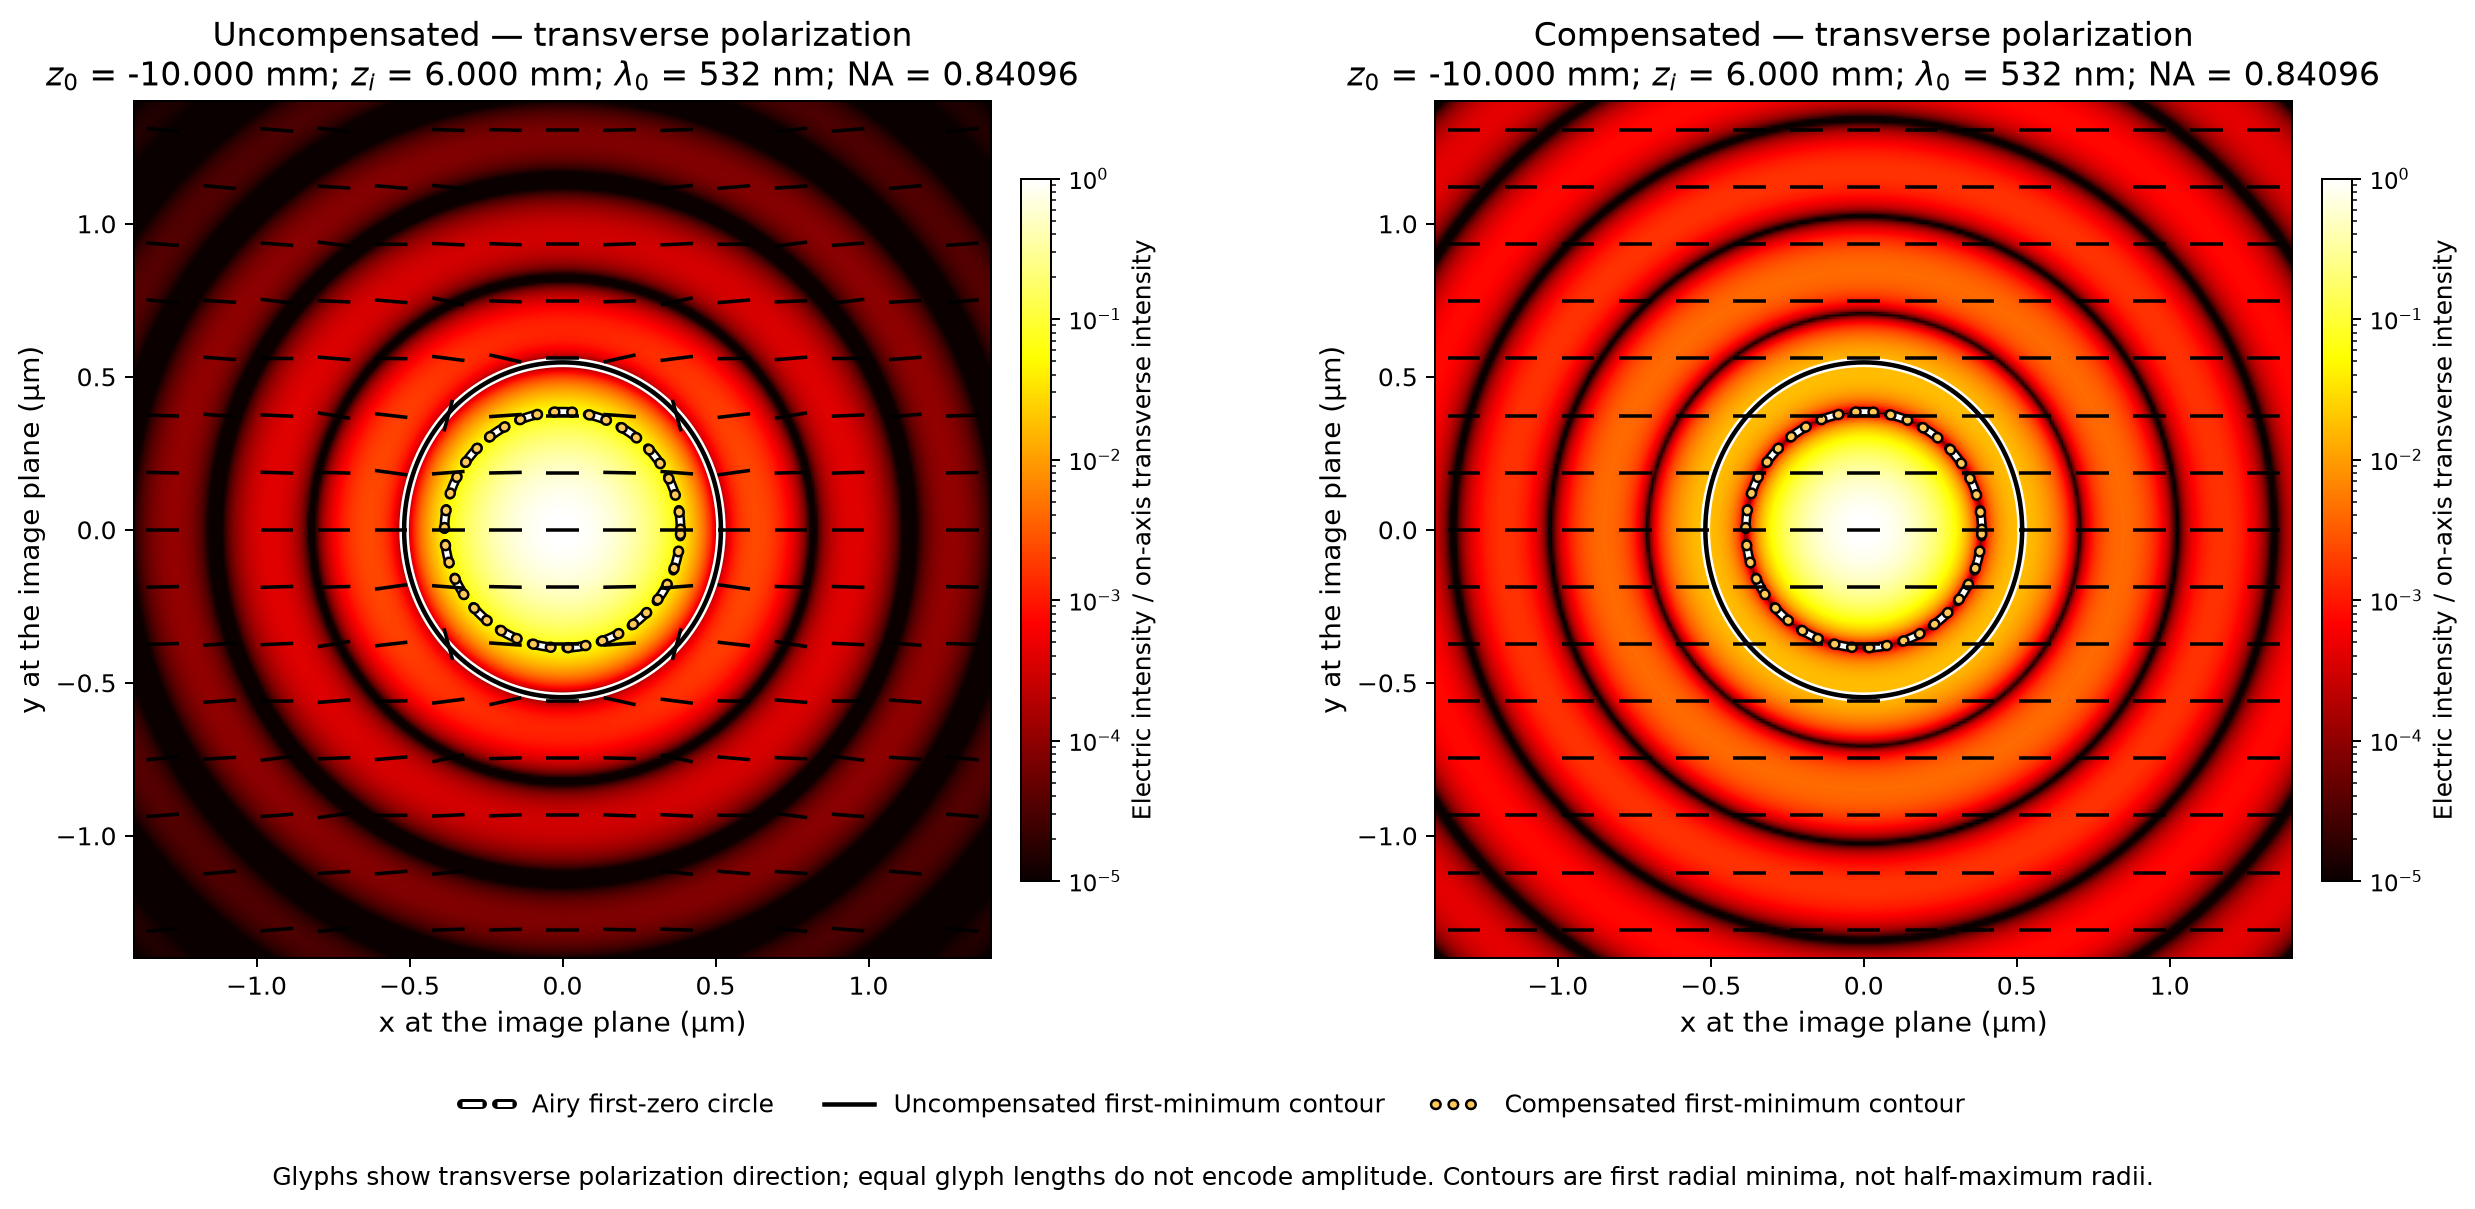

In [4]:
gauss, gauss_weights = np.polynomial.legendre.leggauss(400)
kappa = 0.5 * kappa_max * (gauss + 1)
kappa_weights = 0.5 * kappa_max * gauss_weights
kappa_radius = np.interp(kappa / ki, sine_table, r_table)


def azimuthal_coefficients(amplitudes, kappa_radius=kappa_radius):
    """c0, c2, cz of A(kappa, psi); the ray azimuth is psi + pi."""

    def spectrum(psi):
        ray = rays(kappa_radius, np.full(kappa_radius.shape, psi + np.pi))
        return spectrum_amplitude(ray, *amplitudes(kappa_radius))

    along, across = spectrum(0.0), spectrum(0.5 * np.pi)
    c0 = 0.5 * (along[:, 0] + across[:, 0])
    c2 = 0.5 * (along[:, 0] - across[:, 0])
    cz = along[:, 2]
    # An independent azimuth must follow the x-polarized angular structure.
    psi = 0.37
    model = np.stack((c0 + c2 * np.cos(2 * psi), c2 * np.sin(2 * psi), cz * np.cos(psi)), -1)
    residual = np.max(abs(spectrum(psi) - model)) / np.max(abs(along))
    assert residual < 1e-12, residual
    return c0, c2, cz


def radial_functions(coefficients, rho, kappa=kappa, kappa_weights=kappa_weights):
    c0, c2, cz = coefficients
    argument = np.outer(rho, kappa)
    measure = 2 * np.pi * kappa_weights * kappa
    return (
        jv(0, argument) @ (measure * c0),
        jv(2, argument) @ (measure * c2),
        jv(1, argument) @ (measure * cz),
    )


half_width = 1.40 * um
focal_axis = np.linspace(-half_width, half_width, 281)
X, Y = np.meshgrid(focal_axis, focal_axis)
rho_fine = np.linspace(0, np.sqrt(2) * half_width * 1.01, 6001)
focal_grid = optics.CartesianGrid(focal_axis, focal_axis, optics.Frame(image_point))
coefficients, radial, fields = {}, {}, {}
for name, amplitudes in illuminations.items():
    coefficients[name] = azimuthal_coefficients(amplitudes)
    radial[name] = [CubicSpline(rho_fine, f) for f in radial_functions(coefficients[name], rho_fine)]
    rho, angle = np.hypot(X, Y), np.arctan2(Y, X)
    F0, F2, Fz = (spline(rho) for spline in radial[name])
    values = np.stack(
        (F0 - F2 * np.cos(2 * angle), -F2 * np.sin(2 * angle), 1j * Fz * np.cos(angle)),
        axis=-1,
    )
    fields[name] = optics.ElectricField(focal_grid, wavelength, values)


def transverse_intensity(name, rho, angle):
    F0, F2, _ = (spline(rho) for spline in radial[name])
    return abs(F0 - F2 * np.cos(2 * angle)) ** 2 + abs(F2 * np.sin(2 * angle)) ** 2


def side_lobes(cut):
    """Secondary maxima on each side of the central peak of a focal cut."""
    middle = len(cut) // 2
    inner = cut[1:-1]
    peaks = np.flatnonzero((inner > cut[:-2]) & (inner >= cut[2:])) + 1
    return int(np.sum(peaks < middle)), int(np.sum(peaks > middle))


def first_minimum_contour(name, azimuths):
    """First radial minimum of I_perp at each azimuth, refined parabolically."""
    rho = rho_fine[rho_fine <= half_width]
    intensity = transverse_intensity(name, rho[None, :], azimuths[:, None])
    inner = intensity[:, 1:-1]
    minimum = (inner < intensity[:, :-2]) & (inner <= intensity[:, 2:])
    index = np.argmax(minimum, axis=1) + 1
    rows = np.arange(len(azimuths))
    left, centre, right = (intensity[rows, index + shift] for shift in (-1, 0, 1))
    offset = 0.5 * (left - right) / (left - 2 * centre + right)
    return rho[index] + offset * (rho[1] - rho[0])


middle = len(focal_axis) // 2
for name, field in fields.items():
    transverse = abs(field.Ex) ** 2 + abs(field.Ey) ** 2
    lobes = side_lobes(transverse[middle]), side_lobes(transverse[:, middle])
    print(f"{name}: transverse secondary maxima (left, right) in x, y = {lobes}")
    assert lobes == ((3, 3), (3, 3))

airy_radius = 3.8317059702 / kappa_max
azimuths = np.linspace(0, 2 * np.pi, 721)
contours = {name: first_minimum_contour(name, azimuths) for name in fields}
print(f"Airy first-zero radius r_A = {airy_radius / um:.5f} µm")
for name, contour in contours.items():
    print(
        f"{name} first transverse minimum: x {contour[0] / um:.4f} µm, "
        f"y {contour[180] / um:.4f} µm, range {contour.min() / um:.4f}-{contour.max() / um:.4f} µm"
    )

v = kappa_max * np.hypot(X, Y)
airy = np.ones_like(v)
airy[v > 0] = 2 * j1(v[v > 0]) / v[v > 0]
compensated = fields["Compensated"]
airy_error = np.max(abs(compensated.Ex / compensated.Ex[middle, middle] - airy))
cross = np.max(abs(compensated.Ey)) / abs(compensated.Ex[middle, middle])
print(f"Compensated: max |Ex/Ex(0) - 2J1(v)/v| = {airy_error:.1e}; max |Ey|/|Ex(0)| = {cross:.1e}")
assert airy_error < 1e-9 and cross < 1e-12
assert np.allclose(contours["Compensated"], airy_radius, rtol=1e-4)

# Neutral and warm strokes with a contrasting round-capped halo: every dash
# and dot keeps a complete border on bright lobes and on dark rings.
styles = (
    ("Airy first-zero circle", (0, (4, 3)), "white", "black", 2.0),
    ("Uncompensated first-minimum contour", "-", "black", "white", 1.8),
    ("Compensated first-minimum contour", (0, (0.1, 2.6)), "#ffc857", "black", 2.6),
)
curves = (
    np.full_like(azimuths, airy_radius),
    contours["Uncompensated"],
    contours["Compensated"],
)
figure, axes = plt.subplots(1, 2, figsize=(14, 7))
figure.subplots_adjust(left=0.06, right=0.94, bottom=0.2, top=0.88, wspace=0.42)
for axis, (name, field) in zip(axes, fields.items()):
    on_axis = abs(field.Ex[middle, middle]) ** 2 + abs(field.Ey[middle, middle]) ** 2
    plot_polarization(
        field,
        axis=axis,
        title=f"{name} — transverse polarization\n{parameters}",
        crop=False,
        glyph="line",
        glyph_color="black",
        size_scale=None,
        cmap="hot",
        norm=LogNorm(1e-5, 1),
        reference_intensity=on_axis,
        colorbar_label="Electric intensity / on-axis transverse intensity",
        min_intensity_fraction=1e-5,
    )
    for (label, style, color, halo, width), curve in zip(styles, curves):
        (line,) = axis.plot(
            curve / um * np.cos(azimuths),
            curve / um * np.sin(azimuths),
            linestyle=style,
            color=color,
            lw=width,
            label=label if axis is axes[0] else None,
            path_effects=[
                Stroke(linewidth=width + 2.0, foreground=halo, capstyle="round"),
                Normal(),
            ],
        )
        line.set_dash_capstyle("round" if style == (0, (0.1, 2.6)) else "butt")
    axis.set(xlabel="x at the image plane (µm)", ylabel="y at the image plane (µm)")
figure.legend(loc="lower center", bbox_to_anchor=(0.5, 0.055), ncol=3, frameon=False, fontsize=10)
figure.text(
    0.5,
    0.02,
    "Glyphs show transverse polarization direction; equal glyph lengths do not encode amplitude. "
    "Contours are first radial minima, not half-maximum radii.",
    ha="center",
    fontsize=10,
)
plt.show()

## 5. Transverse profiles against the Airy pattern

The profiles show $I_\perp$ along $x$ and $y$, each normalized to its on-axis value, with the analytic Airy pattern $[2J_1(v)/v]^2$. Vertical lines mark $r_A$ and the uncompensated first minima. For each field we also report the best single complex factor $a$ fitting its transverse field to the Airy amplitude along $x$, $\mathbf E_\perp\approx a\,\frac{2J_1(v)}{v}\,\mathbf e_x$. The residual $\|\mathbf E_\perp-a\,\mathrm{Airy}\,\mathbf e_x\|/\|\mathbf E_\perp\|$ over the window measures the departure from the Airy focus that no uniform gain or global phase can repair. The compensated longitudinal intensity, relative to the transverse on-axis value, is the part the compensation does not prescribe.

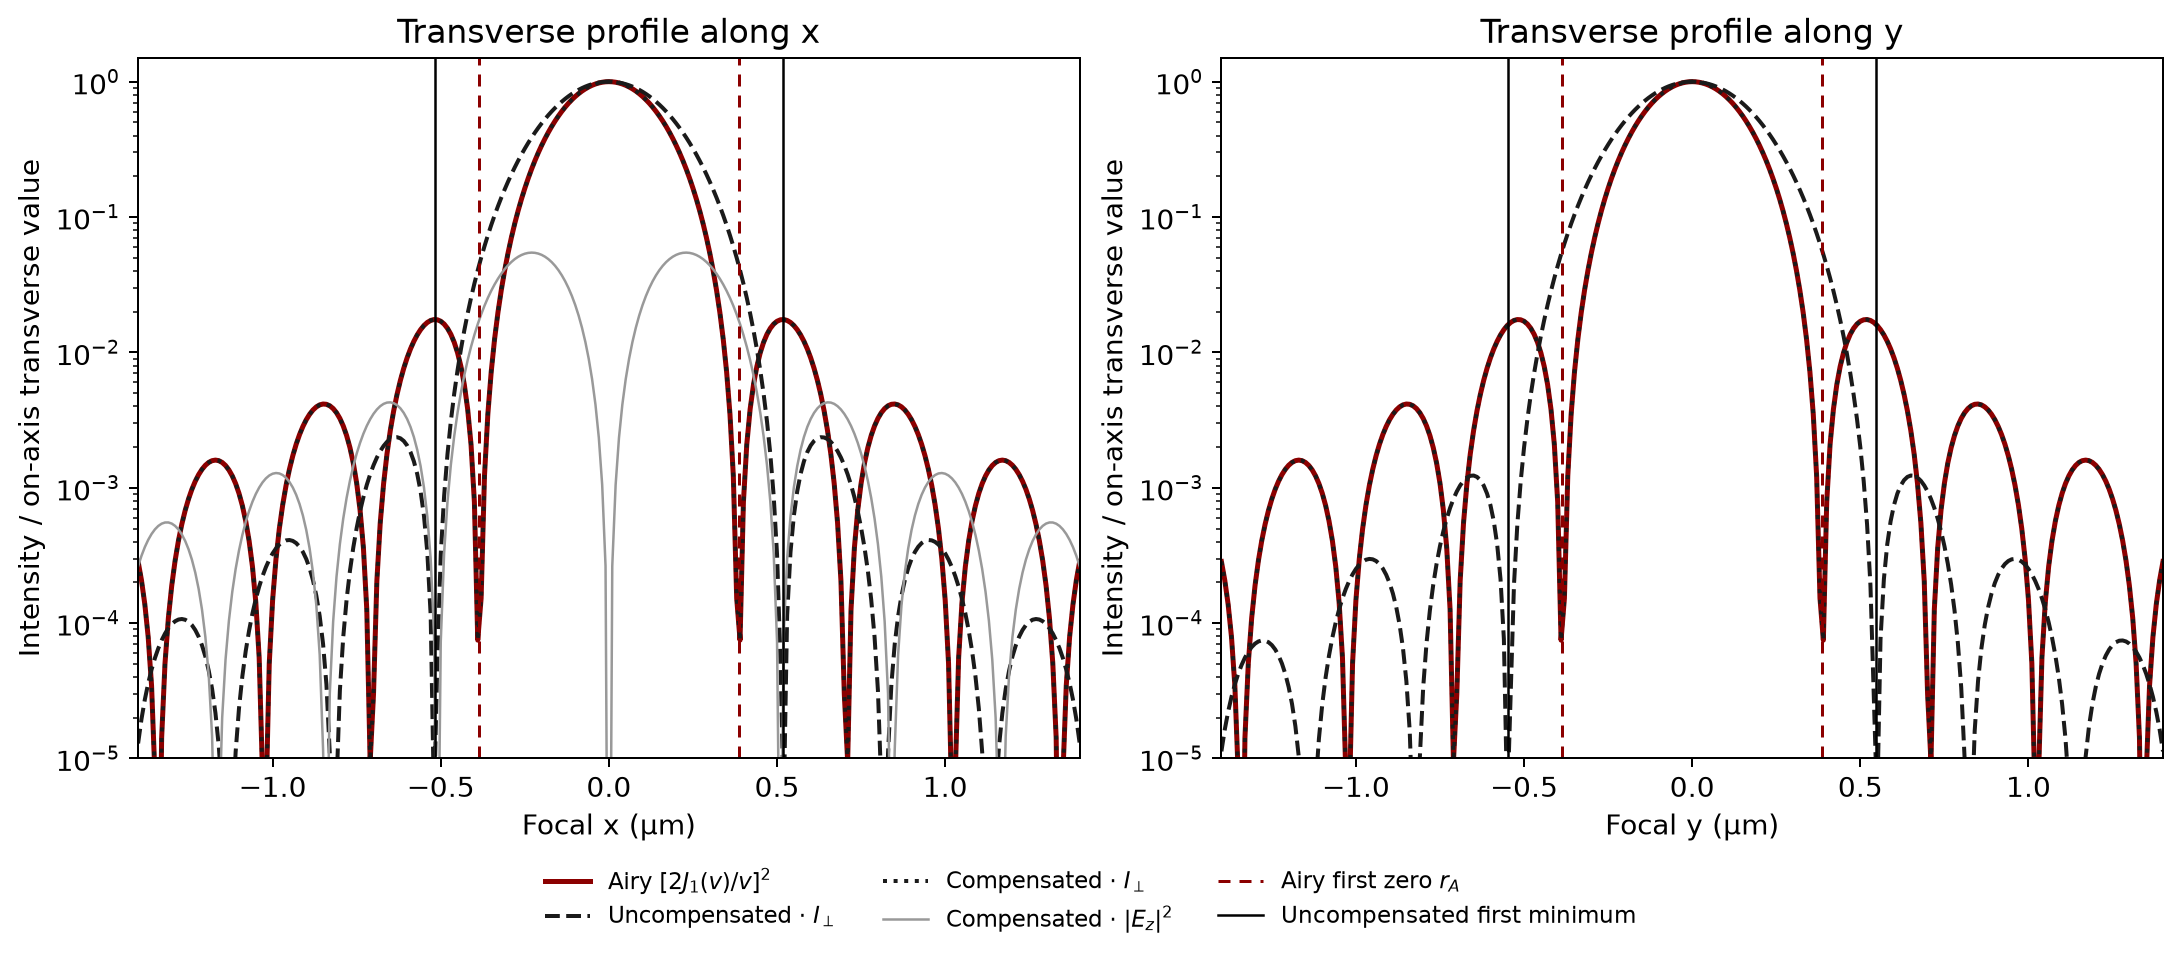

Uncompensated: transverse departure from the Airy focus = 47.2111%
Compensated: transverse departure from the Airy focus = 0.0000%


In [5]:
figure, axes = plt.subplots(1, 2, figsize=(12, 5.2), layout="constrained")
x = focal_axis / um
for axis, (cut, label, index) in zip(
    axes, ((np.s_[middle, :], "x", 0), (np.s_[:, middle], "y", 180))
):
    axis.semilogy(x, np.maximum(airy[cut] ** 2, 1e-8), "-", color="#8B0000", lw=2, label="Airy $[2J_1(v)/v]^2$")
    for (name, field), style in zip(fields.items(), ("--", ":")):
        transverse = abs(field.Ex) ** 2 + abs(field.Ey) ** 2
        axis.semilogy(
            x,
            np.maximum(transverse[cut] / transverse[middle, middle], 1e-8),
            style,
            color="0.1",
            lw=1.6,
            label=f"{name} · $I_\\perp$",
        )
    longitudinal = abs(compensated.Ez) ** 2 / abs(compensated.Ex[middle, middle]) ** 2
    axis.semilogy(x, np.maximum(longitudinal[cut], 1e-8), "-", color="0.6", lw=1, label="Compensated · $|E_z|^2$")
    for sign in (-1, 1):
        axis.axvline(
            sign * airy_radius / um,
            color="#8B0000",
            ls=(0, (4, 3)),
            lw=1.2,
            label="Airy first zero $r_A$" if sign > 0 else None,
        )
        axis.axvline(
            sign * contours["Uncompensated"][index] / um,
            color="black",
            ls="-",
            lw=1.0,
            label="Uncompensated first minimum" if sign > 0 else None,
        )
    axis.set(
        xlabel=f"Focal {label} (µm)",
        ylabel="Intensity / on-axis transverse value",
        title=f"Transverse profile along {label}",
        xlim=(x[0], x[-1]),
        ylim=(1e-5, 1.5),
    )
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False, fontsize=9)
plt.show()

for name, field in fields.items():
    transverse_field = np.stack((field.Ex, field.Ey), axis=-1)
    model = np.zeros_like(transverse_field)
    model[..., 0] = airy
    a = np.vdot(model, transverse_field) / np.vdot(model, model)
    residual = np.linalg.norm(transverse_field - a * model) / np.linalg.norm(transverse_field)
    print(f"{name}: transverse departure from the Airy focus = {residual:.4%}")

## 6. Checks: energy conservation and quadrature

The ray-tube map must carry the power transmitted through $\mathcal G$ into the focal spectrum, $\tfrac{n_i}{2Z_0}(2\pi)^2\int|\mathbf A|^2\cos\theta\,d^2\kappa$. Doubling the number of Gauss–Legendre nodes in $\kappa$ must leave the radial functions unchanged. Both are verified for the two illuminations.

In [6]:
def spectrum_power(amplitudes, count=400):
    nodes, weights = np.polynomial.legendre.leggauss(count)
    k = 0.5 * kappa_max * (nodes + 1)
    wk = 0.5 * kappa_max * weights
    radius = np.interp(k / ki, sine_table, r_table)
    psi = (np.arange(64) + 0.5) * 2 * np.pi / 64
    Rk, Pk = np.meshgrid(radius, psi, indexing="ij")
    ray = rays(Rk, Pk + np.pi)
    A = spectrum_amplitude(ray, *amplitudes(Rk))
    cos_theta = ray["transmitted"][..., 2]
    return ni * (2 * np.pi) ** 2 * np.sum(
        np.sum(abs(A) ** 2, axis=-1) * cos_theta * (wk * k)[:, None] * (2 * np.pi / 64)
    )


rho_check = np.linspace(0, half_width, 401)
for name, amplitudes in illuminations.items():
    balance = spectrum_power(amplitudes) / power[name][1] - 1
    fine_nodes, fine_weights = np.polynomial.legendre.leggauss(800)
    fine_kappa = 0.5 * kappa_max * (fine_nodes + 1)
    fine_coefficients = azimuthal_coefficients(
        amplitudes, np.interp(fine_kappa / ki, sine_table, r_table)
    )
    coarse = np.array(radial_functions(coefficients[name], rho_check))
    fine = np.array(
        radial_functions(fine_coefficients, rho_check, fine_kappa, 0.5 * kappa_max * fine_weights)
    )
    change = np.max(abs(fine - coarse)) / np.max(abs(fine))
    print(
        f"{name}: spectrum power / transmitted power - 1 = {balance:.1e}; "
        f"400 → 800 κ nodes: max radial-function change = {change:.1e}"
    )
    assert abs(balance) < 1e-4 and change < 1e-10

Uncompensated: spectrum power / transmitted power - 1 = 6.9e-10; 400 → 800 κ nodes: max radial-function change = 2.8e-11


Compensated: spectrum power / transmitted power - 1 = -2.6e-11; 400 → 800 κ nodes: max radial-function change = 5.1e-12


**What this experiment establishes.** In a stigmatic diopter the focus is shaped by the surface's own transfer weights: local Fresnel transmission, the tilt of the $p$ field and the energy-conserving ray-tube factor. With constant entrance amplitude these weights fall unequally toward the rim; the focus becomes wider than the Airy radius, elongated along $y$ and depolarized near its dark rings. Dividing the entrance $p$ and $s$ amplitudes by $w_p$ and $w_s$ recovers the Airy pattern exactly in the transverse field, polarized along $x$, at the transmitted power shown in section 2. The longitudinal field is not prescribed. Absorption, surface errors and pupil zeros would require a new compensation analysis.